# Load data and compute missing metrics & rolling means

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

In [3]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [4]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]

# Manual border distance computation

CENTER_X = 2000
CENTER_Y = 1000

df["radius"] = compute_radius(df["X (cm)"], df["Y (cm)"], CENTER_X, CENTER_Y)

In [5]:
df.shape

(9959355, 55)

The history saving thread hit an unexpected error (OperationalError('unable to open database file')).History will not be written to the database.


In [115]:
missing = df[(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]
missing.shape

(0, 55)

In [113]:
radius_filter = df[
    (df["radius"] > 1200)
]

radius_time_filter = df[
    (df["radius"] > 1200) &
    (df["time"] < 60 * 5)
]

print(df.shape)
print(radius_filter.shape)
print(radius_time_filter.shape)


(9143556, 55)
(56658, 55)
(4199, 55)


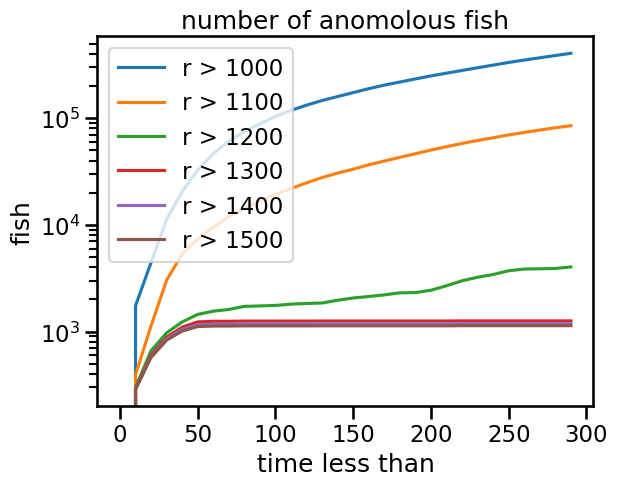

In [114]:
RADII = [1000, 1100, 1200, 1300, 1400, 1500]
TIMES = list(np.arange(0, 300, 10))
for radius in RADII:
    num_removed = []
    for time in TIMES:

        radius_time_filter = df[
            (df["radius"] > radius) &
            (df["time"] < time)
        ]
        num_removed.append(radius_time_filter.shape[0])
        # print(num_removed)
    plt.plot(TIMES, num_removed, label=f"r > {radius}")
plt.xlabel("time less than")
plt.ylabel("fish")
plt.title("number of anomolous fish")
plt.yscale("log")
plt.legend()


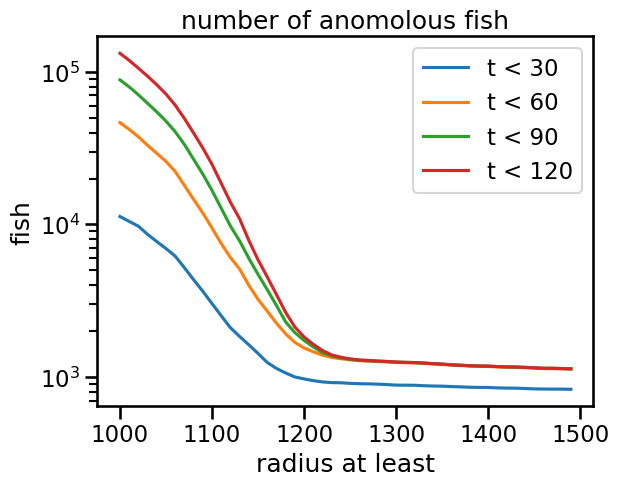

In [111]:
RADII = list(np.arange(1000, 1500, 10))
for time in [30, 60, 90, 120]:
    num_removed = []
    for radius in RADII:
        radius_time_filter = df[
            (df["radius"] > radius) &
            (df["time"] < time)
        ]
        num_removed.append(radius_time_filter.shape[0])
        # print(num_removed)
    plt.plot(RADII, num_removed, label=f"t < {time}")
plt.xlabel("radius at least")
plt.ylabel("fish")
plt.title("number of anomolous fish")
plt.legend()
plt.yscale("log")


In [106]:
_df[["River", "pH", "Trial", "time"]]

,River,pH,Trial,time
535,Green,1,1,38.21
536,Green,1,1,38.29
537,Green,1,1,38.36
538,Green,1,1,38.43
539,Green,1,1,38.50
...,...,...,...,...
9931446,Skagit,3,10,35.40
9931447,Skagit,3,10,35.47
9931448,Skagit,3,10,35.53
9931449,Skagit,3,10,35.60


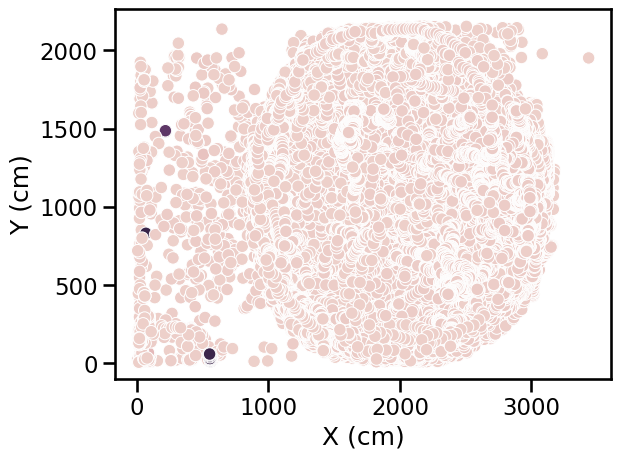

<Axes: xlabel='time', ylabel='Count'>

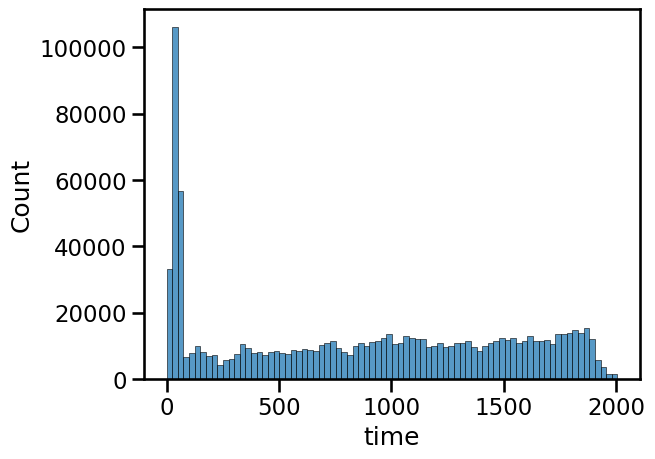

In [24]:
_df = df[
    # (df["radius"] > 1250) &
    (((df["time"] < 60 * 1)) | (df["radius"] > 1400)) &
    # (df["River"] == "Skagit") &
    # (df["pH"] == 1) &
    # (df["Trial"] == 8) &
    True
    ]

sns.scatterplot(data=_df, x="X (cm)", y="Y (cm)", hue="time", legend=False)

plt.show()

sns.histplot(_df["time"])
# sns.histplot(data=_df, x="time")

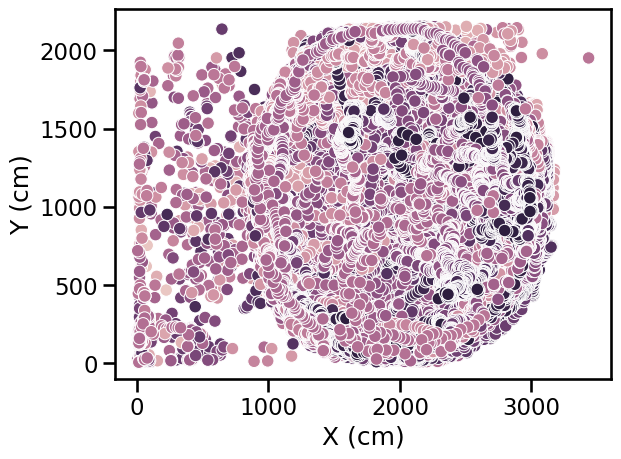

<Axes: xlabel='time', ylabel='Count'>

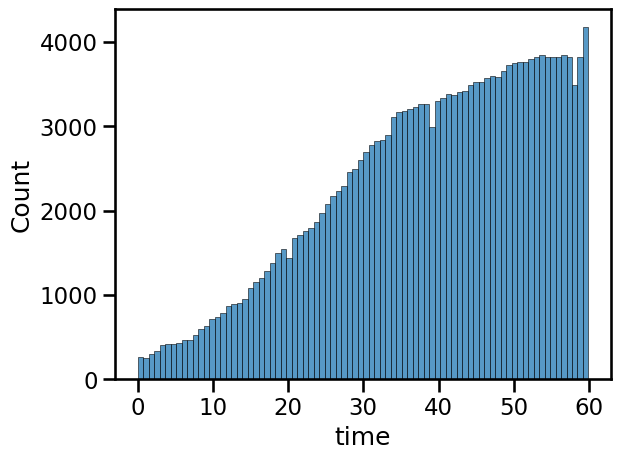

In [17]:
for trial in range(1, 11):
    for river in ["Skagit", "Green"]:
        for pH in 

_df = df[
    # (df["radius"] > 1400) & 
    (df["time"] < 60 * 1) &
    # (df["River"] == "Skagit") &
    # (df["pH"] == 1) &
    # (df["Trial"] == 8) &
    True
    ]

sns.scatterplot(data=_df, x="X (cm)", y="Y (cm)", hue="time", legend=False)

plt.show()

sns.histplot(_df["time"])
# sns.histplot(data=_df, x="time")